# 04. Hyperparameter tuning (Consistency)

**Goal.** For Ridge, Random Forest and Gradient Boosting, find good settings **without looking at the outer test groups**, and check for
under- and over-fitting.

**Nested.** For each outer test group, settings are chosen using only the four validation combinations inside it. The simplest setting
within one standard error of the best is taken.

**Searched.** Ridge `alpha` (11 values, exhaustive); Random Forest and Gradient Boosting (`HistGradientBoostingRegressor`, which reads
missing values) with 30 random settings per feature set; the **feature set**; the **training labels** (rated only, plus propagated
real, plus propagated real and synthetic) and their **weight** (1 or 0.3).

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"  # tiny data: one thread is faster than OpenMP overhead
sys.path.insert(0, str(Path("../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from core import (GROUPS, SEED, Factor, environment, group_bootstrap, load, log_run, log_signed, make_splits, metrics,
                  paired_diff_bootstrap)
from features import (LABEL_SOURCES, Propagator, design, fit_linear, fit_model, fit_ridge_loo, linear_model, make_model, training_set,
                      transform)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

F = Factor(key="consistency", title="Consistency", folder=Path(".").resolve(), dataset_file="consistency_dataset.csv", label="rater_consistency", activity="E_CC")
LABEL, ACT = F.label, F.activity
PROPOSAL = [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus')]
VARIANTS = {'proposal 4': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus')], 'proposal 4 + no-activity flag': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_no_activity', 'raw')], 'proposal 4 + bimodal flag': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_bimodal', 'raw')], 'proposal 4 + first active day': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_first_active_day', 'raw')], '3 features (no CV)': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus')], 'AWR + 1-DC': [('C_AWR', 'raw'), ('C_DC', 'one_minus')], 'AWR only': [('C_AWR', 'raw')], 'commits (log) + AWR': [('E_CC', 'log'), ('C_AWR', 'raw')]}
FEATURES = ['C_AWR', 'C_DC', 'C_LI_norm', 'C_CV_norm']
ZERO_RULE_OK = True
d = load(F)
real = d[d.source == "real"]
syn = d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
active = real[real[ACT] > 0]
print(F.title, d.shape)

Consistency (744, 25)


In [2]:
from sklearn.model_selection import ParameterSampler

N_ITER = 30
splits = pd.read_csv(F.splits)
combos = [(t, v, g[["record_id", "role"]]) for (t, v), g in splits.groupby(["outer_test", "inner_val"])]
GOLD = d[d.label_source == "rater"]
choice = json.loads((F.results / "preprocessing_choice.json").read_text())
SETS = []
for name, base, flags in [('proposal 4', 'proposal 4', {}), ('proposal 4, inactive = missing', 'proposal 4', {'nan_inactive': True})]:
    SETS.append((name, VARIANTS.get(base, PROPOSAL), flags))
chosen_name = "chosen in notebook 03: " + choice["variant"]
if all(VARIANTS[choice["variant"]] != s[1] or s[2] for s in SETS):
    SETS.append((chosen_name, VARIANTS[choice["variant"]], {"zero_rule": choice["zero_rule"]}))
print(environment(F))
print([s[0] for s in SETS])

{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': 'a46a109a5a5c', 'splits_hash': 'b5793a57b501'}
['proposal 4', 'proposal 4, inactive = missing', 'chosen in notebook 03: 3 features (no CV)']


## 1. Search spaces

In [3]:
SPACE = {
    "Ridge": {"alpha": list(np.logspace(-2, 3, 11))},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [2, 3, 4, 6, None], "min_samples_leaf": [1, 2, 3, 5], "max_features": [0.5, 0.75, 1.0]},
    "Gradient Boosting": {"learning_rate": [0.02, 0.05, 0.1, 0.2], "max_iter": [50, 100, 200, 400], "max_depth": [2, 3, 4, None],
                          "min_samples_leaf": [1, 2, 3, 5, 10], "l2_regularization": [0.0, 0.1, 1.0, 10.0], "monotonic": [False, True]},
}
LABEL_OPTIONS = [("rated only", 1.0), ("rated + propagated (real)", 1.0), ("rated + propagated (real)", 0.3),
                 ("rated + propagated (real + synthetic)", 1.0), ("rated + propagated (real + synthetic)", 0.3)]


def settings(name):
    rng = np.random.RandomState(SEED)
    if name == "Ridge":
        return [({"alpha": a}, ls, w) for a in SPACE["Ridge"]["alpha"] for ls, w in LABEL_OPTIONS]
    draws = list(ParameterSampler(SPACE[name], n_iter=N_ITER, random_state=SEED))
    return [(p, *LABEL_OPTIONS[rng.randint(len(LABEL_OPTIONS))]) for p in draws]


print({m: len(settings(m)) for m in SPACE}, "settings per feature set")

{'Ridge': 55, 'Random Forest': 30, 'Gradient Boosting': 30} settings per feature set


## 2. Training sets, built once

In [4]:
def featurize(frame, fs):
    name, spec, flags = fs
    X = design(frame, spec)
    if flags.get("nan_inactive"):
        X[frame[ACT].to_numpy() == 0, :] = np.nan
    return X


_cache = {}


def get_data(ci, fs_i, label_source, weight):
    key = (ci, fs_i, label_source, weight)
    if key not in _cache:
        test, val, roles = combos[ci]
        fs = SETS[fs_i]
        X, y, w, ids = training_set(d, roles, lambda f: featurize(f, fs), LABEL, PROPOSAL, label_source, weight)
        if fs[2].get("zero_rule"):
            keep = d.loc[ids, ACT].to_numpy() > 0
            X, y, w = X[keep], y[keep], w[keep]
        v = d.loc[[i for i in roles[roles.role == "val"].record_id if i in GOLD.index]]
        _cache[key] = (X, y, w, featurize(v, fs), v[LABEL].to_numpy(), v[ACT].to_numpy(), v.record_id.to_numpy())
    return _cache[key]


test, val, roles = combos[0]
X, y, w, Xv, yv, act, rid = get_data(0, 0, "rated + propagated (real)", 1.0)
assert set(rid) <= set(GOLD.index) and not (set(rid) & set(roles[roles.role == "train"].record_id))
print("training rows:", len(y), "| validation rows (rated):", len(yv), "| features:", X.shape[1])

training rows: 45 | validation rows (rated): 4 | features: 4


## 3. Run the search

In [5]:
import time


def evaluate(name, fs_i, params, label_source, weight):
    rows = []
    zero_rule = SETS[fs_i][2].get("zero_rule")
    for ci, (test, val, roles) in enumerate(combos):
        X, y, w, Xv, yv, act, rid = get_data(ci, fs_i, label_source, weight)
        model = fit_model(make_model(name, params, X.shape[1]), name, X, y, w)
        p = np.clip(model.predict(Xv), 0, 1)
        if zero_rule:
            p = np.where(act == 0, 0.0, p)
        err = np.abs(p - yv)
        rows.append((test, val, float(err.mean()), len(err), float(err[act > 0].mean()) if (act > 0).any() else np.nan, float((p - yv).mean())))
    return rows


results, config_id, start = [], 0, time.time()
for name in SPACE:
    for fs_i, fs in enumerate(SETS):
        for params, label_source, weight in settings(name):
            config_id += 1
            for test, val, mae, n, mae_active, bias in evaluate(name, fs_i, params, label_source, weight):
                results.append((config_id, name, fs[0], json.dumps(params), label_source, weight, test, val, mae, n, mae_active, bias))
    print(f"{name}: done, {config_id} settings so far, {time.time() - start:.0f}s")
tune = pd.DataFrame(results, columns=["config_id", "model", "feature_set", "params", "label_source", "weight", "outer_test", "inner_val", "MAE", "n", "MAE_active", "bias"])
tune.to_csv(F.results / "tuning_results.csv", index=False)
print(len(tune), "evaluations;", tune.config_id.nunique(), "settings")

Ridge: done, 165 settings so far, 203s


Random Forest: done, 255 settings so far, 720s


Gradient Boosting: done, 345 settings so far, 1034s
6900 evaluations; 345 settings


## 4. Choosing the settings: per outer test group, using only its inner validation

A setting's score is its mean MAE over the four validation groups inside the outer fold. The best has the lowest score; the **simplest
setting within one standard error of it** is chosen.

In [6]:
def complexity(row):
    p = json.loads(row.params)
    label_rank = LABEL_SOURCES.index(row.label_source) + (0.5 if row.weight != 1.0 else 0)
    if row.model == "Ridge":
        return (label_rank, -p["alpha"])
    if row.model == "Random Forest":
        return (label_rank, p["n_estimators"] * (p["max_depth"] or 10))
    return (label_rank, p["max_iter"] * (p["max_depth"] or 6) * p["learning_rate"] + (0 if p["monotonic"] else 0.001))


score = (tune.groupby(["model", "feature_set", "outer_test", "config_id"])
         .agg(MAE=("MAE", "mean"), SE=("MAE", lambda s: s.std(ddof=1) / np.sqrt(len(s))), label_source=("label_source", "first"),
              weight=("weight", "first"), params=("params", "first")).reset_index())
chosen_rows = []
for (model, fs, outer), g in score.groupby(["model", "feature_set", "outer_test"]):
    best = g.loc[g.MAE.idxmin()]
    near = g[g.MAE <= best.MAE + best.SE].copy()
    near["complexity"] = near.apply(complexity, axis=1)
    pick = near.sort_values("complexity").iloc[0]
    chosen_rows.append({"model": model, "feature_set": fs, "outer_test": outer, "config_id": int(pick.config_id), "inner_MAE": pick.MAE,
                        "best_inner_MAE": best.MAE, "n_within_1SE": len(near), "label_source": pick.label_source, "weight": pick.weight, "params": pick.params})
chosen = pd.DataFrame(chosen_rows)
summary = (chosen.groupby(["model", "feature_set"]).agg(inner_MAE=("inner_MAE", "mean"), spread_over_folds=("inner_MAE", "std"),
                                                         best_possible=("best_inner_MAE", "mean")).round(4).sort_values("inner_MAE"))
summary

inner_MAE  spread_over_folds  best_possible
model             feature_set                                                                           
Gradient Boosting proposal 4                                    0.0664             0.0113         0.0624
                  proposal 4, inactive = missing                0.0671             0.0120         0.0624
Ridge             proposal 4                                    0.0673             0.0095         0.0579
                  proposal 4, inactive = missing                0.0692             0.0074         0.0588
Random Forest     proposal 4                                    0.0705             0.0146         0.0656
                  proposal 4, inactive = missing                0.0710             0.0142         0.0663
Ridge             chosen in notebook 03: 3 features (no CV)     0.0762             0.0067         0.0661
Gradient Boosting chosen in notebook 03: 3 features (no CV)     0.0762             0.0224         0.0660
Random Forest     chosen in notebook 03: 3 features (no CV)     0.0830             0.0295         0.0701

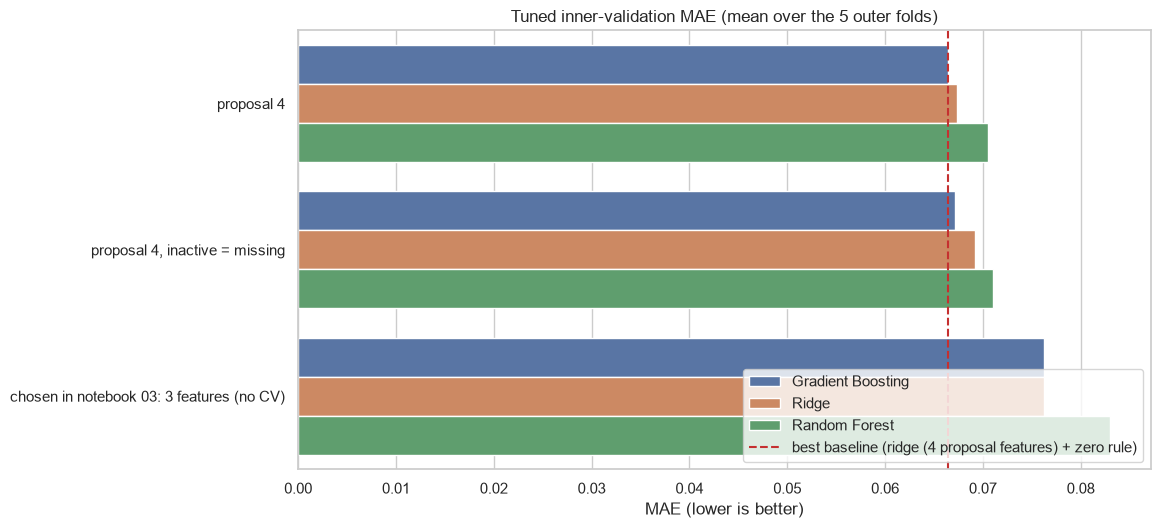

In [7]:
ref = pd.read_csv(F.results / "runs.csv")
ref = ref[ref.notebook == "02_splits_and_baselines"].set_index("model").MAE
fig, ax = plt.subplots(figsize=(11, 0.9 * len(SETS) + 3))
sns.barplot(data=summary.reset_index(), y="feature_set", x="inner_MAE", hue="model", ax=ax, palette="deep")
ax.axvline(ref.min(), color="#c53030", ls="--", label=f"best baseline ({ref.idxmin()})")
ax.set(title="Tuned inner-validation MAE (mean over the 5 outer folds)", xlabel="MAE (lower is better)", ylabel="")
ax.legend(loc="lower right")
plt.show()

## 5. How sensitive is each model to its settings?

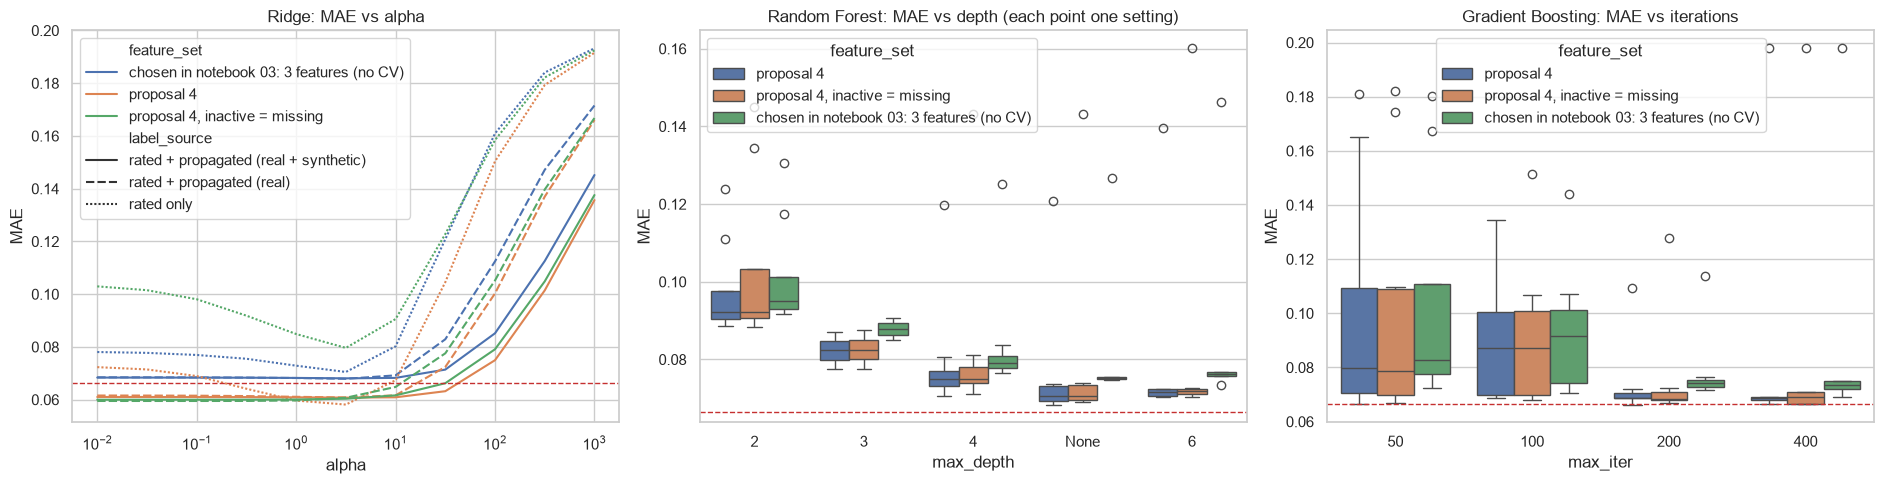

min  median    max
model             feature_set                                                    
Gradient Boosting chosen in notebook 03: 3 features (no CV)  0.069   0.077  0.198
                  proposal 4                                 0.066   0.072  0.198
                  proposal 4, inactive = missing             0.067   0.071  0.198
Random Forest     chosen in notebook 03: 3 features (no CV)  0.074   0.079  0.146
                  proposal 4                                 0.068   0.076  0.140
                  proposal 4, inactive = missing             0.069   0.076  0.160
Ridge             chosen in notebook 03: 3 features (no CV)  0.068   0.069  0.193
                  proposal 4                                 0.058   0.062  0.192
                  proposal 4, inactive = missing             0.059   0.063  0.192

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
r = tune[tune.model == "Ridge"].copy()
r["alpha"] = r.params.map(lambda s: json.loads(s)["alpha"])
sns.lineplot(data=r.groupby(["feature_set", "alpha", "label_source"]).MAE.mean().reset_index(), x="alpha", y="MAE", hue="feature_set", style="label_source", ax=axes[0])
axes[0].set(xscale="log", title="Ridge: MAE vs alpha")
f = tune[tune.model == "Random Forest"].copy()
f["max_depth"] = f.params.map(lambda s: str(json.loads(s)["max_depth"]))
sns.boxplot(data=f.groupby(["config_id", "feature_set", "max_depth"]).MAE.mean().reset_index(), x="max_depth", y="MAE", hue="feature_set", ax=axes[1])
axes[1].set(title="Random Forest: MAE vs depth (each point one setting)")
g = tune[tune.model == "Gradient Boosting"].copy()
g["max_iter"] = g.params.map(lambda s: json.loads(s)["max_iter"])
sns.boxplot(data=g.groupby(["config_id", "feature_set", "max_iter"]).MAE.mean().reset_index(), x="max_iter", y="MAE", hue="feature_set", ax=axes[2])
axes[2].set(title="Gradient Boosting: MAE vs iterations")
for a in axes:
    a.axhline(ref.min(), color="#c53030", ls="--", lw=1)
plt.tight_layout()
plt.show()
tune.groupby(["model", "feature_set", "config_id"]).MAE.mean().groupby(["model", "feature_set"]).agg(["min", "median", "max"]).round(3)

## 6. Under- and over-fitting: learning curves

For the best feature set of each model: train on 25%, 50%, 75% and 100% of the training rows (three random draws, at least 4 rows) and
compare the error on the training rows with the error on the validation rows.

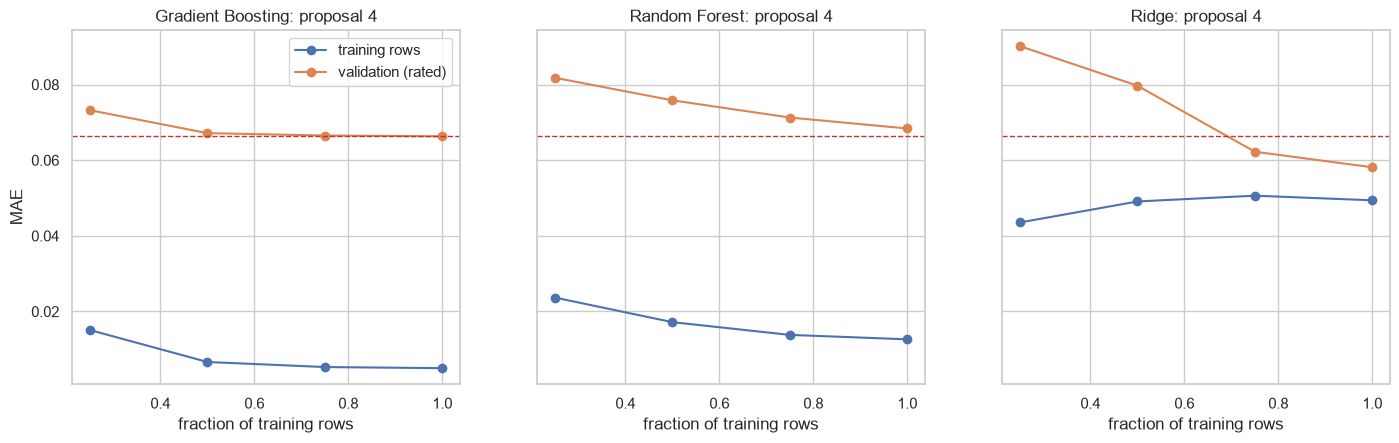

,model,fraction of training rows,train MAE,validation MAE
0,Gradient Boosting,0.25,0.015,0.073
1,Gradient Boosting,0.50,0.007,0.067
2,Gradient Boosting,0.75,0.005,0.067
3,Gradient Boosting,1.00,0.005,0.066
4,Random Forest,0.25,0.024,0.082
5,Random Forest,0.50,0.017,0.076
6,Random Forest,0.75,0.014,0.071
7,Random Forest,1.00,0.013,0.068
8,Ridge,0.25,0.044,0.090
9,Ridge,0.50,0.049,0.080


In [9]:
def best_config(model):
    name = summary.reset_index().query("model == @model").sort_values("inner_MAE").iloc[0].feature_set
    fs_i = [s[0] for s in SETS].index(name)
    g = tune[(tune.model == model) & (tune.feature_set == name)].groupby("config_id").MAE.mean()
    row = tune[tune.config_id == g.idxmin()].iloc[0]
    return fs_i, json.loads(row.params), row.label_source, row.weight


curves, rng = [], np.random.RandomState(SEED)
for model in SPACE:
    fs_i, params, label_source, weight = best_config(model)
    for frac in (0.25, 0.5, 0.75, 1.0):
        for draw in range(3 if frac < 1 else 1):
            tr, va = [], []
            for ci in range(len(combos)):
                X, y, w, Xv, yv, act, rid = get_data(ci, fs_i, label_source, weight)
                k = max(4, int(round(frac * len(y))))
                idx = rng.choice(len(y), min(k, len(y)), replace=False) if frac < 1 else np.arange(len(y))
                m = fit_model(make_model(model, params, X.shape[1]), model, X[idx], y[idx], w[idx])
                tr.append(np.average(np.abs(np.clip(m.predict(X[idx]), 0, 1) - y[idx]), weights=w[idx]))
                va.append(np.abs(np.clip(m.predict(Xv), 0, 1) - yv).mean())
            curves.append((model, frac, np.mean(tr), np.mean(va)))
lc = pd.DataFrame(curves, columns=["model", "fraction of training rows", "train MAE", "validation MAE"]).groupby(["model", "fraction of training rows"]).mean().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for a, (model, g) in zip(axes, lc.groupby("model")):
    a.plot(g["fraction of training rows"], g["train MAE"], "o-", label="training rows")
    a.plot(g["fraction of training rows"], g["validation MAE"], "o-", label="validation (rated)")
    a.axhline(ref.min(), color="#c53030", ls="--", lw=1)
    a.set(title=f"{model}: {SETS[best_config(model)[0]][0]}", xlabel="fraction of training rows")
axes[0].set_ylabel("MAE")
axes[0].legend()
plt.show()
lc.round(3)

## 7. Save the choices and log

In [10]:
out = {}
for (model, fs), g in chosen.groupby(["model", "feature_set"]):
    out.setdefault(model, {})[fs] = {r.outer_test: {"params": json.loads(r.params), "label_source": r.label_source, "weight": float(r.weight),
                                                    "inner_MAE": round(float(r.inner_MAE), 4)} for r in g.itertuples()}
(F.results / "tuning_choices.json").write_text(json.dumps(out, indent=1))
for r in summary.reset_index().itertuples():
    log_run(F, "04_hyperparameter_tuning", r.model, f"{r.feature_set}; nested inner validation, mean of 5 outer folds", {"MAE": round(r.inner_MAE, 4), "SE": round(r.spread_over_folds, 4)})
print("saved training/results/tuning_choices.json and tuning_results.csv; logged to runs.csv")

saved training/results/tuning_choices.json and tuning_results.csv; logged to runs.csv


## 8. Reading the results

Tuned **inner-validation MAE** (mean over the 5 outer folds, settings chosen per fold on its own validation groups):

| Model | proposal 4 | proposal 4, inactive = missing | chosen in 03 (3 features) |
|---|---|---|---|
| Gradient Boosting | **0.066** | 0.067 | 0.076 |
| Ridge | 0.067 | 0.069 | 0.076 |
| Random Forest | 0.071 | 0.071 | 0.083 |

The untuned Ridge on the proposal's four features scored 0.0665 in notebook 02.

- **Tuning bought almost nothing.** The best tuned model (boosting, 0.0664) equals the untuned Ridge baseline (0.0665). The median setting is
  0.062 for Ridge and 0.072-0.076 for the tree models, and the best 0.058-0.068, so settings matter within a narrow band; a few poor ones
  (large alpha, very shallow trees) reach 0.14-0.20.
- **All four proposal features beat the three-feature set** for every model (0.066-0.071 vs 0.076-0.083): the simplicity rule's choice in
  notebook 03 costs about 0.01 here. Marking inactive students as missing does not help (0.067-0.071).
- **Under- and over-fitting.** Ridge's validation error keeps falling as rows are added (0.090 -> 0.058) and ends close to its training error
  (0.049): a well-matched, slightly under-fitted model. Forest and boosting fit their training rows almost perfectly (0.013 and 0.005) but
  validate at 0.068 and 0.066, and their validation error flattens by about 75% of the data.
- **Propagated labels** are used by the tuned models here too, since the label model is accurate for this factor (notebook 03).
- The tuned scores are best-of-many on the same validation groups, so they are optimistic; notebook 05 removes that bias.

Saved: `training/results/tuning_choices.json`, `tuning_results.csv`. Next: **05. Model comparison**.